In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
from pathlib import Path
data_path = Path("Data/raw/data.csv")
if not data_path.exists():
    data_path = Path("../Data/raw/data.csv")
df = pd.read_csv(data_path, encoding="utf-8-sig")
df.columns = df.columns.str.strip()


In [3]:
print("shape of the dataset:", df.shape)
print("number of missing values:", df.isna().sum().sum())
print("number of duplicate rows:", df.duplicated().sum())

shape of the dataset: (6819, 96)
number of missing values: 0
number of duplicate rows: 0


In [4]:
df.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),Net Value Per Share (A),Net Value Per Share (C),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Revenue Per Share (Yuan ¥),Operating Profit Per Share (Yuan ¥),Per Share Net profit before tax (Yuan ¥),Realized Sales Gross Profit Growth Rate,Operating Profit Growth Rate,After-tax Net Profit Growth Rate,Regular Net Profit Growth Rate,Continuous Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Total Asset Return Growth Rate Ratio,Cash Reinvestment %,Current Ratio,Quick Ratio,Interest Expense Ratio,Total debt/Total net worth,Debt ratio %,Net worth/Assets,Long-term fund suitability ratio (A),Borrowing dependency,Contingent liabilities/Net worth,Operating profit/Paid-in capital,Net profit before tax/Paid-in capital,Inventory and accounts receivable/Net value,Total Asset Turnover,Accounts Receivable Turnover,Average Collection Days,Inventory Turnover Rate (times),Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Allocation rate per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Quick Assets/Current Liability,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Inventory/Working Capital,Inventory/Current Liability,Current Liabilities/Liability,Working Capital/Equity,Current Liabilities/Equity,Long-term Liability to Current Assets,Retained Earnings to Total Assets,Total income/Total expense,Total expense/Assets,Current Asset Turnover Rate,Quick Asset Turnover Rate,Working capitcal Turnover Rate,Cash Turnover Rate,Cash Flow to Sales,Fixed Assets to Assets,Current Liability to Liability,Current Liability to Equity,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,0.780985,1.256969e-04,0.0,0.458143,0.000725,0.0,0.147950,0.147950,0.147950,0.169141,0.311664,0.017560,0.095921,0.138736,0.022102,0.848195,0.688979,0.688979,0.217535,4.980000e+09,0.000327,0.263100,0.363725,0.002259,0.001208,0.629951,0.021266,0.207576,0.792424,0.005024,0.390284,0.006479,0.095885,0.137757,0.398036,0.086957,0.001814,0.003487,1.820926e-04,1.165007e-04,0.032903,0.034164,0.392913,0.037135,0.672775,0.166673,0.190643,0.004094,0.001997,1.473360e-04,0.147308,0.334015,0.276920,0.001036,0.676269,0.721275,0.339077,0.025592,0.903225,0.002022,0.064856,7.010000e+08,6.550000e+09,0.593831,4.580000e+08,0.671568,0.424206,0.676269,0.339077,0.126549,0.637555,0.458609,0.520382,0.312905,0.118250,0,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,0.781506,2.897851e-04,0.0,0.461867,0.000647,0.0,0.182251,0.182251,0.182251,0.208944,0.318137,0.021144,0.093722,0.169918,0.022080,0.848088,0.689693,0.689702,0.217620,6.110000e+09,0.000443,0.264516,0.376709,0.006016,0.004039,0.635172,0.012502,0.171176,0.828824,0.005059,0.376760,0.005835,0.093743,0.168962,0.397725,0.064468,0.001286,0.004917,9.360000e+09,7.190000e+08,0.025484,0.0068

In [5]:
df.columns

Index(['Bankrupt?', 'ROA(C) before interest and depreciation before interest',
       'ROA(A) before interest and % after tax',
       'ROA(B) before interest and depreciation after tax',
       'Operating Gross Margin', 'Realized Sales Gross Margin',
       'Operating Profit Rate', 'Pre-tax net Interest Rate',
       'After-tax net Interest Rate',
       'Non-industry income and expenditure/revenue',
       'Continuous interest rate (after tax)', 'Operating Expense Rate',
       'Research and development expense rate', 'Cash flow rate',
       'Interest-bearing debt interest rate', 'Tax rate (A)',
       'Net Value Per Share (B)', 'Net Value Per Share (A)',
       'Net Value Per Share (C)', 'Persistent EPS in the Last Four Seasons',
       'Cash Flow Per Share', 'Revenue Per Share (Yuan ¥)',
       'Operating Profit Per Share (Yuan ¥)',
       'Per Share Net profit before tax (Yuan ¥)',
       'Realized Sales Gross Profit Growth Rate',
       'Operating Profit Growth Rate', 'After-tax

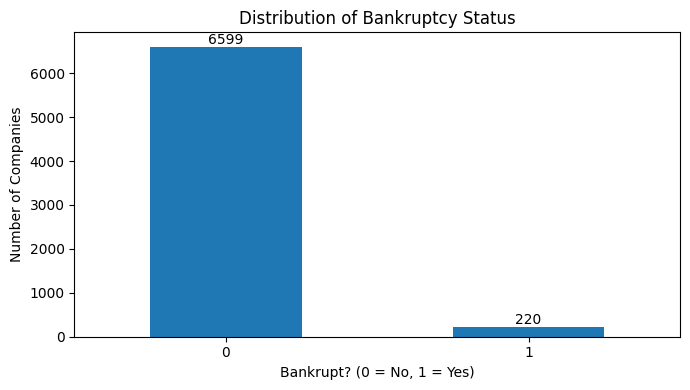

In [6]:
target_counts = df["Bankrupt?"].value_counts().sort_index()
ax = target_counts.plot(kind="bar", figsize=(7, 4))
ax.set_title("Distribution of Bankruptcy Status")
ax.set_xlabel("Bankrupt? (0 = No, 1 = Yes)")
ax.set_ylabel("Number of Companies")
ax.set_xticklabels([str(x) for x in target_counts.index], rotation=0)
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()


In [7]:
target = "Bankrupt?"

features = [col for col in df.columns if col != target]

print("Number of features:", len(features))
print("\nFeature names:")

for i, col in enumerate(features, start=1):
    print(f"{i}. {col}")

Number of features: 95

Feature names:
1. ROA(C) before interest and depreciation before interest
2. ROA(A) before interest and % after tax
3. ROA(B) before interest and depreciation after tax
4. Operating Gross Margin
5. Realized Sales Gross Margin
6. Operating Profit Rate
7. Pre-tax net Interest Rate
8. After-tax net Interest Rate
9. Non-industry income and expenditure/revenue
10. Continuous interest rate (after tax)
11. Operating Expense Rate
12. Research and development expense rate
13. Cash flow rate
14. Interest-bearing debt interest rate
15. Tax rate (A)
16. Net Value Per Share (B)
17. Net Value Per Share (A)
18. Net Value Per Share (C)
19. Persistent EPS in the Last Four Seasons
20. Cash Flow Per Share
21. Revenue Per Share (Yuan ¥)
22. Operating Profit Per Share (Yuan ¥)
23. Per Share Net profit before tax (Yuan ¥)
24. Realized Sales Gross Profit Growth Rate
25. Operating Profit Growth Rate
26. After-tax Net Profit Growth Rate
27. Regular Net Profit Growth Rate
28. Continuous 

In [8]:
df.columns=df.columns.str.strip()# to remove any leading or trailing whitespace from the column names

In [9]:
# ============================================================
# 1. PROFITABILITY, RETURNS & MARGINS
# Measures how well a company generates profit from its assets,
# sales, and equity (الربحية والعائد وهوامش الأرباح).
# ============================================================

profitability_features = [
    "ROA(C) before interest and depreciation before interest",
    "ROA(A) before interest and % after tax",
    "ROA(B) before interest and depreciation after tax",
    "Operating Gross Margin",
    "Realized Sales Gross Margin",
    "Operating Profit Rate",
    "Pre-tax net Interest Rate",
    "After-tax net Interest Rate",
    "Non-industry income and expenditure/revenue",
    "Continuous interest rate (after tax)",
    "Operating profit/Paid-in capital",
    "Net profit before tax/Paid-in capital",
    "Retained Earnings to Total Assets",
    "Total income/Total expense",
    "Net Income to Total Assets",
    "Gross Profit to Sales",
    "Net Income to Stockholder's Equity"
]


# ============================================================
# 2. GROWTH & REINVESTMENT
# Measures changes in company assets, profits, net value,
# and reinvestment (النمو وإعادة استثمار الأموال).
# ============================================================

growth_features = [
    "Realized Sales Gross Profit Growth Rate",
    "Operating Profit Growth Rate",
    "After-tax Net Profit Growth Rate",
    "Regular Net Profit Growth Rate",
    "Continuous Net Profit Growth Rate",
    "Total Asset Growth Rate",
    "Net Value Growth Rate",
    "Total Asset Return Growth Rate Ratio",
    "Cash Reinvestment %"
]


# ============================================================
# 3. LIQUIDITY & WORKING CAPITAL
# Measures the ability to meet short-term obligations using
# cash, current assets, and working capital (السيولة ورأس المال العامل).
# ============================================================

liquidity_features = [
    "Current Ratio",
    "Quick Ratio",
    "Working Capital to Total Assets",
    "Quick Assets/Total Assets",
    "Current Assets/Total Assets",
    "Cash/Total Assets",
    "Quick Assets/Current Liability",
    "Cash/Current Liability",
    "Current Liability to Assets",
    "Inventory/Working Capital",
    "Inventory/Current Liability",
    "Current Liabilities/Liability",
    "Working Capital/Equity",
    "Current Liabilities/Equity",
    "Current Liability to Current Assets",
    "No-credit Interval",
    "Long-term Liability to Current Assets"
]


# ============================================================
# 4. LEVERAGE & SOLVENCY
# Measures debt, liabilities, equity, and the company's ability
# to handle its financial obligations (الديون والملاءة المالية).
# ============================================================

leverage_features = [
    "Interest Expense Ratio",
    "Total debt/Total net worth",
    "Debt ratio %",
    "Net worth/Assets",
    "Long-term fund suitability ratio (A)",
    "Borrowing dependency",
    "Contingent liabilities/Net worth",
    "Current Liability to Liability",
    "Current Liability to Equity",
    "Equity to Long-term Liability",
    "Liability-Assets Flag",
    "Liability to Equity",
    "Degree of Financial Leverage (DFL)",
    "Interest Coverage Ratio (Interest expense to EBIT)",
    "Equity to Liability"
]


# ============================================================
# 5. OPERATING EFFICIENCY & TURNOVER
# Measures how efficiently assets, inventory, and receivables
# are used to generate revenue (الكفاءة التشغيلية ومعدلات الدوران).
# ============================================================

efficiency_features = [
    "Inventory and accounts receivable/Net value",
    "Total Asset Turnover",
    "Accounts Receivable Turnover",
    "Average Collection Days",
    "Inventory Turnover Rate (times)",
    "Fixed Assets Turnover Frequency",
    "Net Worth Turnover Rate (times)",
    "Current Asset Turnover Rate",
    "Quick Asset Turnover Rate",
    "Working capitcal Turnover Rate",
    "Cash Turnover Rate",
    "Fixed Assets to Assets"
]


# ============================================================
# 6. CASH FLOW & FUNDING
# Measures cash generated by operations and how cash flow
# relates to liabilities, assets, sales, and equity
# (التدفقات النقدية والقدرة على توليد النقد).
# ============================================================

cashflow_features = [
    "Cash flow rate",
    "Operating Funds to Liability",
    "Cash Flow to Sales",
    "Cash Flow to Total Assets",
    "Cash Flow to Liability",
    "CFO to Assets",
    "Cash Flow to Equity"
]


# ============================================================
# 7. PER-SHARE & WORKFORCE PRODUCTIVITY
# Measures financial performance per share or per employee
# (مؤشرات السهم وإنتاجية العاملين).
# ============================================================

pershare_workforce_features = [
    "Net Value Per Share (B)",
    "Net Value Per Share (A)",
    "Net Value Per Share (C)",
    "Persistent EPS in the Last Four Seasons",
    "Cash Flow Per Share",
    "Revenue Per Share (Yuan ¥)",
    "Operating Profit Per Share (Yuan ¥)",
    "Per Share Net profit before tax (Yuan ¥)",
    "Revenue per person",
    "Operating profit per person",
    "Allocation rate per person"
]


# ============================================================
# 8. EXPENSES, FINANCING COST & OTHER INDICATORS
# Covers operating expenses, R&D costs, interest costs, taxes,
# company scale relative to GNP, and special indicator variables
# (المصروفات وتكاليف التمويل والضرائب ومؤشرات إضافية).
# ============================================================

expenses_other_features = [
    "Operating Expense Rate",
    "Research and development expense rate",
    "Interest-bearing debt interest rate",
    "Tax rate (A)",
    "Total expense/Assets",
    "Total assets to GNP price",
    "Net Income Flag"
]




In [10]:
feature_groups = {
    "Profitability": profitability_features, "Growth": growth_features,
    "Liquidity": liquidity_features, "Leverage": leverage_features,
    "Operating Efficiency": efficiency_features, "Cash Flow": cashflow_features,
    "Per-share & Workforce": pershare_workforce_features,
    "Expenses & Other": expenses_other_features,
}


In [11]:

for group_name, group_features in feature_groups.items():
    group_df = df[group_features]

    # Count columns with only one unique value
    constant_cols = [
        col for col in group_features
        if df[col].nunique(dropna=False) <= 1
    ]

    # Count infinite values
    infinite_counts = np.isinf(group_df).sum()

    # Count outliers using the IQR rule
    Q1 = group_df.quantile(0.25)
    Q3 = group_df.quantile(0.75)
    IQR = Q3 - Q1

    outlier_mask = (
        (group_df < Q1 - 1.5 * IQR) |
        (group_df > Q3 + 1.5 * IQR)
    )

    print(f"\n{'=' * 50}")
    print(f"Group: {group_name}")
    print(f"Number of features: {len(group_features)}")
    print(f"Constant columns: {constant_cols}")
    print(f"Missing values: {group_df.isna().sum().sum()}")
    print(f"Infinite values: {infinite_counts.sum()}")
    print(f"Outlier cells (IQR): {outlier_mask.sum().sum()}")



Group: Profitability
Number of features: 17
Constant columns: []
Missing values: 0
Infinite values: 0
Outlier cells (IQR): 9748

Group: Growth
Number of features: 9
Constant columns: []
Missing values: 0
Infinite values: 0
Outlier cells (IQR): 8391

Group: Liquidity
Number of features: 17
Constant columns: []
Missing values: 0
Infinite values: 0
Outlier cells (IQR): 7250

Group: Leverage
Number of features: 15
Constant columns: []
Missing values: 0
Infinite values: 0
Outlier cells (IQR): 8713

Group: Operating Efficiency
Number of features: 12
Constant columns: []
Missing values: 0
Infinite values: 0
Outlier cells (IQR): 5594

Group: Cash Flow
Number of features: 7
Constant columns: []
Missing values: 0
Infinite values: 0
Outlier cells (IQR): 5544

Group: Per-share & Workforce
Number of features: 11
Constant columns: []
Missing values: 0
Infinite values: 0
Outlier cells (IQR): 6155

Group: Expenses & Other
Number of features: 7
Constant columns: ['Net Income Flag']
Missing values: 0
I

In [12]:
df["Net Income Flag"].value_counts()

Net Income Flag
1    6819
Name: count, dtype: int64

In [13]:
df["Bankrupt?"].value_counts()

Bankrupt?
0    6599
1     220
Name: count, dtype: int64

In [14]:
target = "Bankrupt?"

features = df.drop(columns=[target]).select_dtypes(
    include="number"
).columns

summary = df.groupby(target)[features].agg(["mean", "median"])

# Compare medians between the two classes
medians = df.groupby(target)[features].median().T
medians.columns = ["Non_Bankrupt", "Bankrupt"]

medians["Absolute_Difference"] = (
    medians["Bankrupt"] - medians["Non_Bankrupt"]
).abs()

print("Features with the largest absolute median differences:")
display(
    medians.sort_values(
        "Absolute_Difference", ascending=False
    ).head(15)
)


Features with the largest absolute median differences:


,Non_Bankrupt,Bankrupt,Absolute_Difference
Total Asset Growth Rate,6.440000e+09,5.420000e+09,1.020000e+09
Research and development expense rate,5.430000e+08,1.545000e+08,3.885000e+08
Cash Turnover Rate,1.060000e+09,1.305000e+09,2.450000e+08
Inventory Turnover Rate (times),7.335294e-04,5.160000e+07,5.160000e+07
Quick Assets/Total Assets,3.889452e-01,2.716794e-01,1.172658e-01
Fixed Assets to Assets,1.945862e-01,2.899987e-01,9.541249e-02
Tax rate (A),8.158721e-02,0.000000e+00,8.158721e-02
Current Assets/Total Assets,5.166639e-01,4.363738e-01,8.029016e-02
Debt ratio %,1.093811e-01,1.874263e-01,7.804517e-02
Net worth/Assets,8.906189e-01,8.125737e-01,7.804517e-02


# EDA Conclusions: What Can This Dataset Support?

**Scope:** This notebook stops before model training. The goal is to use the actual dataset and EDA evidence to decide:
1. which ML tasks are supported,
2. which features are sensible candidates,
3. which simulation ideas are feasible,
4. what data-quality issues must be resolved before training.

The target is `Bankrupt?`. This is a Taiwanese corporate bankruptcy benchmark, not a direct label for Egyptian startup success. No values are corrected or removed in this notebook.

In [15]:
# Target audit: class balance and a deliberately simple baseline
target = "Bankrupt?"
target_counts = df[target].value_counts().sort_index()
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": (target_counts / len(df) * 100).round(2)
})
display(target_summary)

majority_accuracy = target_counts.max() / len(df)
print(f"Majority-class baseline accuracy: {majority_accuracy:.2%}")
print("Interpretation: predicting every company as non-bankrupt would reach this accuracy,")
print("but it would detect zero of the bankrupt companies. Accuracy alone is unsuitable.")

,Count,Percentage
Bankrupt?,,
0,6599,96.77
1,220,3.23


Majority-class baseline accuracy: 96.77%
Interpretation: predicting every company as non-bankrupt would reach this accuracy,
but it would detect zero of the bankrupt companies. Accuracy alone is unsuitable.


## 1. Data integrity and extreme-scale values

The earlier IQR scan found many outliers. An IQR flag is not proof of an error, so this section uses an explicit **triage threshold** of `abs(value) >= 1,000,000` to identify suspiciously large magnitudes for investigation. This threshold is not a financial rule.

**Important:** do not delete, cap, divide, or log-transform these values until their meaning is checked against the source/data dictionary. Some turnover/growth fields may have unusual encodings, but this CSV alone does not establish why.

In [16]:
target = "Bankrupt?"
X = df.drop(columns=[target]).select_dtypes(include="number")

non_finite_count = int((~np.isfinite(X.to_numpy())).sum())
constant_features = X.columns[X.nunique(dropna=False) <= 1].tolist()
extreme_threshold = 1_000_000
extreme_mask = X.abs() >= extreme_threshold

quality_summary = pd.DataFrame({
    "Metric": [
        "Rows", "Columns including target", "Predictor count",
        "Missing cells", "Duplicate rows", "Non-finite predictor cells",
        "Constant predictors", "Predictor cells |x| >= 1,000,000",
        "Features with at least one |x| >= 1,000,000",
        "Rows with at least one |x| >= 1,000,000",
    ],
    "Value": [
        len(df), df.shape[1], X.shape[1],
        int(df.isna().sum().sum()), int(df.duplicated().sum()),
        non_finite_count, len(constant_features),
        int(extreme_mask.sum().sum()), int(extreme_mask.any(axis=0).sum()),
        int(extreme_mask.any(axis=1).sum()),
    ]
})
display(quality_summary)

print("Constant predictors:", constant_features)

extreme_by_feature = pd.DataFrame({
    "Extreme_Count": extreme_mask.sum(),
    "Extreme_Percentage": (extreme_mask.mean() * 100).round(2),
    "Minimum": X.min(),
    "Median": X.median(),
    "Maximum": X.max(),
})
display(
    extreme_by_feature[extreme_by_feature["Extreme_Count"] > 0]
    .sort_values("Extreme_Count", ascending=False)
    .head(30)
)

,Metric,Value
0,Rows,6819
1,Columns including target,96
2,Predictor count,95
3,Missing cells,0
4,Duplicate rows,0
5,Non-finite predictor cells,0
6,Constant predictors,1
7,"Predictor cells |x| >= 1,000,000",24934
8,"Features with at least one |x| >= 1,000,000",24
9,"Rows with at least one |x| >= 1,000,000",6761


Constant predictors: ['Net Income Flag']


,Extreme_Count,Extreme_Percentage,Minimum,Median,Maximum
Total Asset Growth Rate,6016,88.22,0.0,6.400000e+09,9.990000e+09
Cash Turnover Rate,4238,62.15,0.0,1.080000e+09,1.000000e+10
Research and development expense rate,4033,59.14,0.0,5.090000e+08,9.980000e+09
Inventory Turnover Rate (times),2946,43.20,0.0,7.646743e-04,9.990000e+09
Quick Asset Turnover Rate,2383,34.95,0.0,2.247728e-04,1.000000e+10
Operating Expense Rate,2278,33.41,0.0,2.777589e-04,9.990000e+09
Current Asset Turnover Rate,1234,18.10,0.0,1.987816e-04,1.000000e+10
Fixed Assets Turnover Frequency,1228,18.01,0.0,5.930942e-04,9.990000e+09
Interest-bearing debt interest rate,221,3.24,0.0,3.210321e-04,9.900000e+08
Long-term Liability to Current Assets,109,1.60,0.0,1.974619e-03,9.540000e+09


## 2. Distribution and skewness profile

This summary helps decide which features need closer inspection and whether scaling or transformations may be needed later. Skewness and large values are diagnostic signals, **not automatic reasons to remove a feature**.

For a linear model, scaling and possibly a carefully chosen transformation may matter. Tree-based models are usually less sensitive to feature scaling, but they can still be affected by bad or corrupted values.

In [17]:
feature_profile = pd.DataFrame(index=X.columns)
feature_profile["Unique_Values"] = X.nunique(dropna=False)
feature_profile["Skewness"] = X.skew(numeric_only=True)
feature_profile["P01"] = X.quantile(0.01)
feature_profile["Median"] = X.median()
feature_profile["P99"] = X.quantile(0.99)
feature_profile["Minimum"] = X.min()
feature_profile["Maximum"] = X.max()
feature_profile["Extreme_Count_abs_ge_1e6"] = extreme_mask.sum()

print("Most skewed features by absolute skewness:")
display(
    feature_profile.assign(Abs_Skewness=feature_profile["Skewness"].abs())
    .sort_values("Abs_Skewness", ascending=False)
    .head(20)
)

print("Features with the largest extreme-scale counts:")
display(
    feature_profile.sort_values("Extreme_Count_abs_ge_1e6", ascending=False)
    .head(20)
)

Most skewed features by absolute skewness:


,Unique_Values,Skewness,P01,Median,P99,Minimum,Maximum,Extreme_Count_abs_ge_1e6,Abs_Skewness
Fixed Assets to Assets,6814,82.577237,0.003751,0.196881,0.790928,0.0,8.320000e+09,1,82.577237
Current Ratio,6132,82.577237,0.002390,0.010587,0.074595,0.0,2.750000e+09,1,82.577237
Total income/Total expense,6819,82.332424,0.001835,0.002336,0.003721,0.0,1.000000e+00,0,82.332424
Net Value Growth Rate,4502,80.291844,0.000324,0.000462,0.001199,0.0,9.330000e+09,2,80.291844
Contingent liabilities/Net worth,1855,79.670620,0.005366,0.005366,0.010043,0.0,1.000000e+00,0,79.670620
Realized Sales Gross Profit Growth Rate,5583,77.925109,0.021671,0.022102,0.024486,0.0,1.000000e+00,0,77.925109
Operating Profit Growth Rate,6249,-71.688950,0.846386,0.848044,0.850907,0.0,1.000000e+00,0,71.688950
Operating Profit Rate,3376,-70.237164,0.997582,0.999022,0.999403,0.0,1.000000e+00,0,70.237164
Continuous Net Profit Growth Rate,6270,67.097534,0.216612,0.217598,0.218559,0.0,1.000000e+00,0,67.097534
Total Asset Return Growth Rate Ratio,2903,62.499961,0.261876,0.264050,0.267758,0.0,1.000000e+00,0,62.499961


Features with the largest extreme-scale counts:


,Unique_Values,Skewness,P01,Median,P99,Minimum,Maximum,Extreme_Count_abs_ge_1e6
Total Asset Growth Rate,1751,-0.918791,0.000102,6.400000e+09,9.758200e+09,0.0,9.990000e+09,6016
Cash Turnover Rate,4023,0.954117,0.000103,1.080000e+09,9.620000e+09,0.0,1.000000e+10,4238
Research and development expense rate,1536,1.282043,0.000000,5.090000e+08,9.440000e+09,0.0,9.980000e+09,4033
Inventory Turnover Rate (times),2397,1.137289,0.000102,7.646743e-04,9.730000e+09,0.0,9.990000e+09,2946
Quick Asset Turnover Rate,5377,1.137353,0.000102,2.247728e-04,9.830000e+09,0.0,1.000000e+10,2383
Operating Expense Rate,2966,1.248673,0.000102,2.777589e-04,9.790000e+09,0.0,9.990000e+09,2278
Current Asset Turnover Rate,6261,2.115956,0.000102,1.987816e-04,9.788200e+09,0.0,1.000000e+10,1234
Fixed Assets Turnover Frequency,2451,2.349803,0.000104,5.930942e-04,9.460000e+09,0.0,9.990000e+09,1228
Interest-bearing debt interest rate,1080,7.033377,0.000000,3.210321e-04,7.582000e+08,0.0,9.900000e+08,221
Long-term Liability to Current Assets,4249,12.401607,0.000000,1.974619e-03,1.398200e+09,0.0,9.540000e+09,109


## 3. Which features are associated with the target?

The table below ranks features by the absolute **Spearman correlation** with `Bankrupt?`. This is an exploratory association screen, not a final feature-selection decision and not evidence of causation. With 95 features, multiple comparisons and correlated ratios matter; the strongest-looking features must be checked for data quality and stability before they are selected for a model.

In [18]:
# Spearman correlation is rank-based and can be useful for skewed features.
# Constant columns produce undefined correlations and are excluded from ranking.
spearman_to_target = df.corr(method="spearman", numeric_only=True)[target].drop(target)
target_association = pd.DataFrame({
    "Spearman_Correlation_with_Target": spearman_to_target,
    "Absolute_Correlation": spearman_to_target.abs(),
    "Median_Non_Bankrupt": df.loc[df[target] == 0, X.columns].median(),
    "Median_Bankrupt": df.loc[df[target] == 1, X.columns].median(),
})
display(
    target_association.sort_values("Absolute_Correlation", ascending=False).head(25)
)

,Spearman_Correlation_with_Target,Absolute_Correlation,Median_Non_Bankrupt,Median_Bankrupt
Persistent EPS in the Last Four Seasons,-0.238209,0.238209,0.225111,0.195944
Net Income to Total Assets,-0.234316,0.234316,0.811492,0.766297
Net profit before tax/Paid-in capital,-0.233106,0.233106,0.179021,0.154012
Per Share Net profit before tax (Yuan ¥),-0.232442,0.232442,0.180236,0.155306
Retained Earnings to Total Assets,-0.229533,0.229533,0.938058,0.912923
Continuous interest rate (after tax),-0.227621,0.227621,0.781639,0.781347
Total income/Total expense,-0.224564,0.224564,0.002343,0.002048
ROA(B) before interest and depreciation after tax,-0.224163,0.224163,0.553563,0.488597
ROA(C) before interest and depreciation before interest,-0.223589,0.223589,0.504314,0.441330
ROA(A) before interest and % after tax,-0.222410,0.222410,0.561219,0.490215


## 4. Redundant and highly correlated features

Highly correlated financial ratios may carry overlapping information. That can make a linear model's coefficients unstable and can make feature-importance values hard to separate. It does not automatically mean one feature is wrong or must be removed; use domain definitions and model validation before deciding.

The code reports pairs with absolute Spearman correlation of at least 0.95.

In [19]:
corr = X.corr(method="spearman")
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

pair_rows = []
for col in upper.columns:
    for row, value in upper[col].dropna().items():
        if abs(value) >= 0.95:
            pair_rows.append({
                "Feature_1": row,
                "Feature_2": col,
                "Spearman_Correlation": value,
                "Absolute_Correlation": abs(value)
            })

correlated_pairs = pd.DataFrame(pair_rows)
if correlated_pairs.empty:
    print("No pairs met the |Spearman correlation| >= 0.95 threshold.")
else:
    display(
        correlated_pairs.sort_values("Absolute_Correlation", ascending=False)
        .reset_index(drop=True)
    )

,Feature_1,Feature_2,Spearman_Correlation,Absolute_Correlation
0,Debt ratio %,Net worth/Assets,-1.000000,1.000000
1,Current Liabilities/Equity,Current Liability to Equity,1.000000,1.000000
2,Current Liabilities/Liability,Current Liability to Liability,1.000000,1.000000
3,Net worth/Assets,Equity to Liability,1.000000,1.000000
4,Debt ratio %,Equity to Liability,-1.000000,1.000000
5,Operating Gross Margin,Gross Profit to Sales,1.000000,1.000000
6,Net Value Per Share (B),Net Value Per Share (A),0.999948,0.999948
7,Operating Profit Per Share (Yuan ¥),Operating profit/Paid-in capital,0.999484,0.999484
8,Net Value Per Share (A),Net Value Per Share (C),0.999441,0.999441
9,Net Value Per Share (B),Net Value Per Share (C),0.999390,0.999390


## 5. Visual comparison of representative financial features

These plots focus on interpretable indicators rather than all 95 columns at once. For readability only, each plotted feature is clipped to its own 1st–99th percentile **in a temporary plotting copy**. The original `df` is not changed. If a feature's distribution is dominated by suspicious extreme values, its plot must not be treated as a clean business interpretation.

/tmp/ipykernel_619/1814343495.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([values_0, values_1], labels=["0", "1"], showfliers=False)
/tmp/ipykernel_619/1814343495.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([values_0, values_1], labels=["0", "1"], showfliers=False)
/tmp/ipykernel_619/1814343495.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([values_0, values_1], labels=["0", "1"], showfliers=False)
/tmp/ipykernel_619/1814343495.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support fo

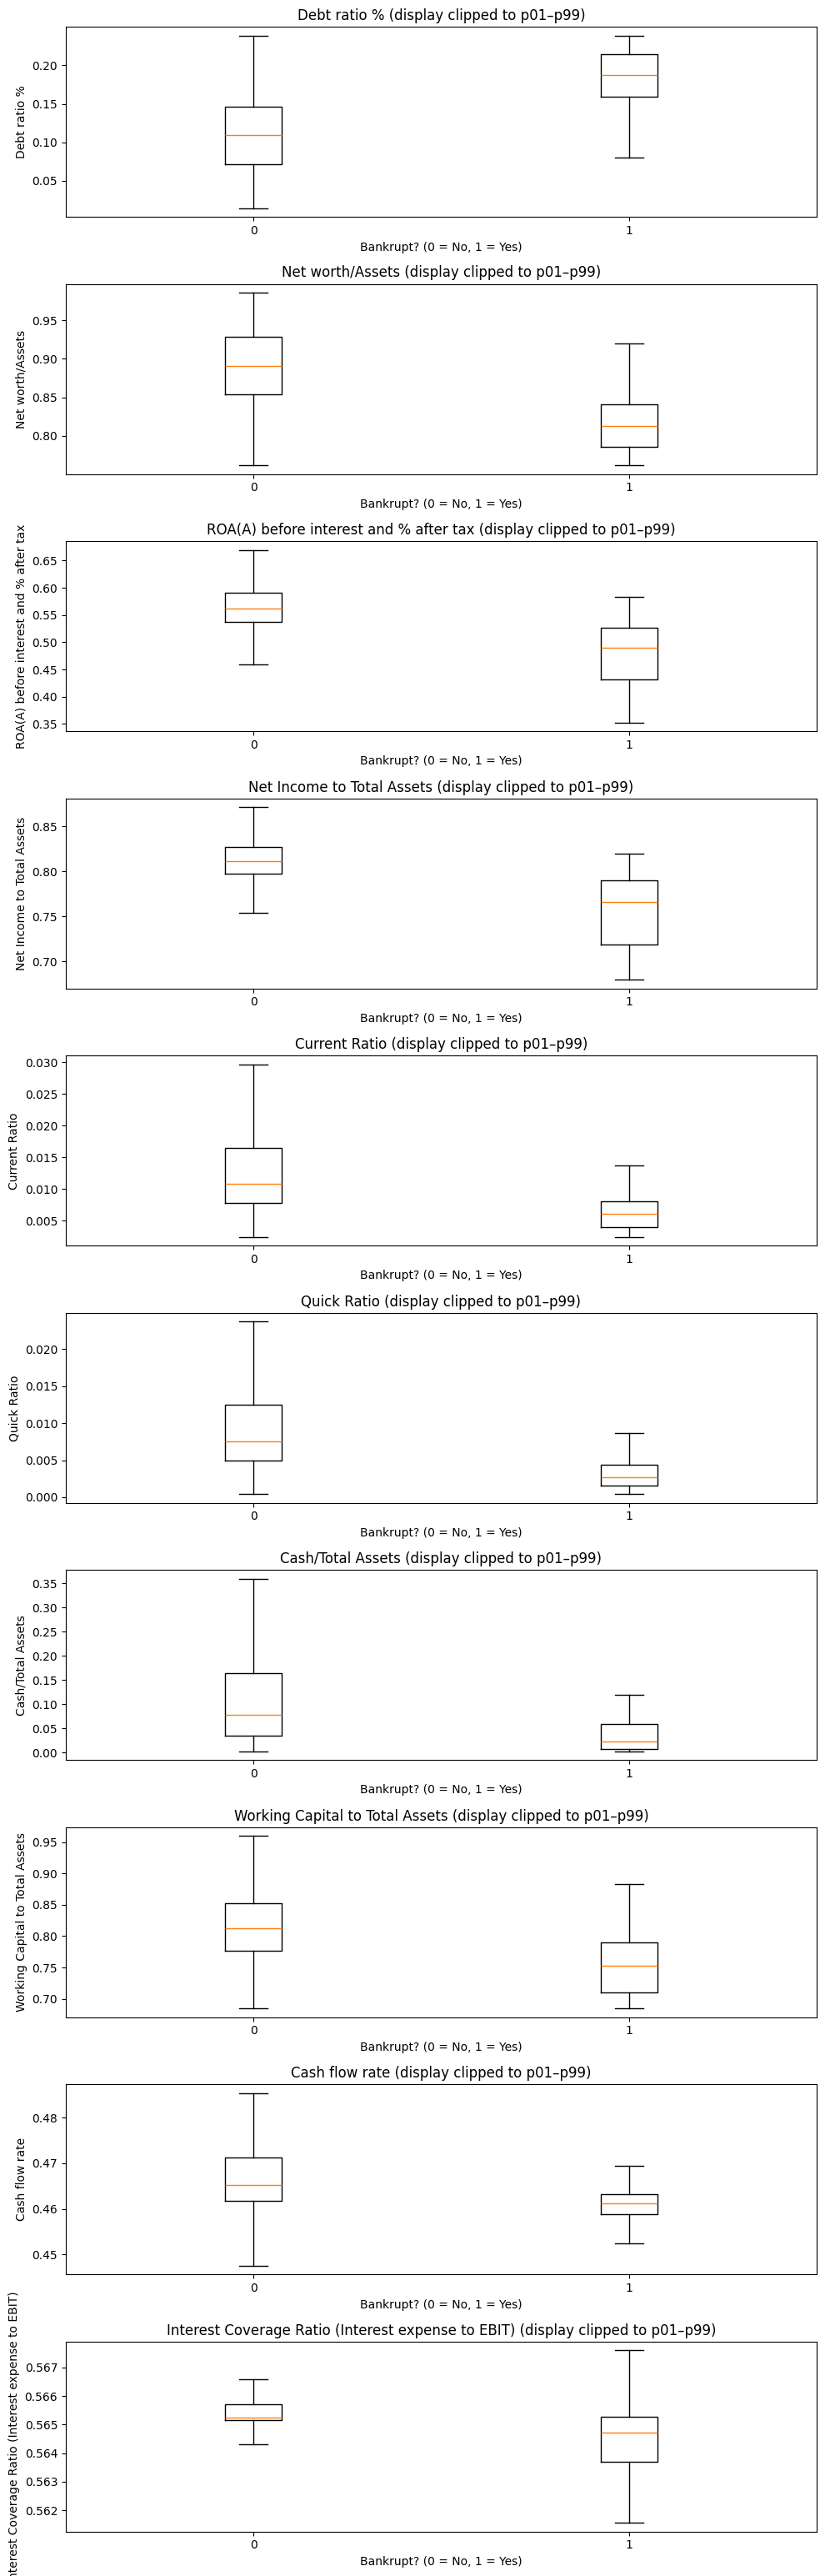

In [20]:
representative_features = [
    "Debt ratio %",
    "Net worth/Assets",
    "ROA(A) before interest and % after tax",
    "Net Income to Total Assets",
    "Current Ratio",
    "Quick Ratio",
    "Cash/Total Assets",
    "Working Capital to Total Assets",
    "Cash flow rate",
    "Interest Coverage Ratio (Interest expense to EBIT)",
]

available_plot_features = [c for c in representative_features if c in df.columns]
fig, axes = plt.subplots(
    nrows=len(available_plot_features), ncols=1,
    figsize=(10, 3.1 * len(available_plot_features))
)
if len(available_plot_features) == 1:
    axes = [axes]

for ax, feature in zip(axes, available_plot_features):
    low, high = df[feature].quantile([0.01, 0.99])
    values_0 = df.loc[df[target] == 0, feature].clip(lower=low, upper=high).dropna()
    values_1 = df.loc[df[target] == 1, feature].clip(lower=low, upper=high).dropna()
    ax.boxplot([values_0, values_1], labels=["0", "1"], showfliers=False)
    ax.set_title(f"{feature} (display clipped to p01–p99)")
    ax.set_xlabel("Bankrupt? (0 = No, 1 = Yes)")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


## 6. Candidate models supported by this dataset (no training performed)

### A. Main supervised task: Bankruptcy Classification
- **Target:** `Bankrupt?` (binary).
- **Inputs:** the 95 financial predictors, after resolving data-quality issues and making a documented preprocessing plan.
- **Outputs:** predicted class and, if probability estimates are calibrated/validated, an estimated bankruptcy probability.
- **Candidate algorithms to compare later:** Logistic Regression as a baseline; Random Forest; gradient-boosted trees such as XGBoost/LightGBM if available.
- **Evaluation:** PR-AUC, recall, precision, specificity, calibration and threshold-specific confusion matrices. The positive class is only 3.23%, so accuracy alone is misleading.
- **No separate model is needed just to output a class, a probability, and a risk band.** Those can be outputs of the same fitted classifier, with a validated threshold for the risk band.

### B. Optional unsupervised task: Financial-profile clustering
- **Goal:** group firms with similar financial profiles.
- **Possible methods:** K-Means or hierarchical clustering, only after robust preprocessing and feature scaling.
- **Limitation:** clusters are not bankruptcy predictions and are not inherently meaningful risk groups. Interpret and validate them before assigning business labels.

### C. Optional unsupervised task: Anomaly detection
- **Goal:** flag financial profiles that are unusual relative to this dataset.
- **Possible method:** Isolation Forest.
- **Limitation:** unusual does not mean bankrupt or fraudulent. The extreme-scale data issue must be resolved first.

### What the current dataset does not support by itself
- Startup success prediction: there is no separately defined success label.
- Revenue/profit/growth forecasting: no future continuous target or time series is provided.
- Time-to-bankruptcy/survival modelling: no company timelines or event dates are provided.
- A validated Egypt-specific startup model: this benchmark is Taiwanese corporate data and contains no Egyptian cohort or local startup fields.

## 7. Feature shortlist for later investigation (not a final selection)

Use these as a **candidate pool**, not as a claim that they are already the best model features. They were selected for financial interpretability and relevance to bankruptcy risk; final inclusion must depend on source validation, leakage checks, redundancy, and validation performance.

| Financial theme | Candidate features | Why investigate them |
|---|---|---|
| Profitability | `ROA(A) before interest and % after tax`, `Net Income to Total Assets`, `Operating Profit Rate` | Profit generation relative to assets/operations |
| Leverage / solvency | `Debt ratio %`, `Net worth/Assets`, `Current Liability to Assets`, `Borrowing dependency` | Debt burden and financial structure |
| Liquidity | `Current Ratio`, `Quick Ratio`, `Cash/Total Assets`, `Working Capital to Total Assets` | Ability to cover near-term obligations |
| Cash flow | `Cash flow rate`, `Cash Flow to Liability`, `CFO to Assets` | Cash generation relative to obligations/assets |
| Interest coverage | `Interest Coverage Ratio (Interest expense to EBIT)`, `Interest Expense Ratio` | Ability to cover financing costs |
| Operating efficiency | `Total Asset Turnover`, `Average Collection Days` | Asset use and receivables collection |

**Redundancy warning:** `Debt ratio %` and `Net worth/Assets` are strongly related in this dataset (their absolute Spearman correlation was reported as 1.0 in the earlier analysis). Do not interpret them as two independent signals. The constant `Net Income Flag` has no variation and therefore provides no predictive information in this file; it should be excluded from a later fitted model. Keep other rare flags under review rather than automatically deleting them.

## 8. Simulation ideas and what is realistically possible

A model-based **what-if sensitivity tool** can be built later: change a chosen feature or scenario, run the same bankruptcy classifier, and compare predicted probabilities. This is a simulation of the model's response, not proof of a causal financial effect.

| Simulation idea | Feasibility from this dataset | Conditions / limitations |
|---|---|---|
| Compare predicted risk for the current profile vs. a hypothetical profile | Feasible after training a validated classifier | New values must be within plausible ranges and match the training feature definitions |
| Change one leverage or liquidity indicator and observe model response | Technically feasible as a sensitivity experiment | Ratios are interdependent; changing one ratio alone may create an impossible financial profile |
| Compare several hypothetical scenarios | Feasible as model-based scenario comparison | Scenarios need documented assumptions and plausibility checks |
| Simulate monthly cash burn, runway, revenue, or expenses | Not supported by this dataset alone | Requires raw financial statements or monthly cash/revenue/expense data |
| Claim that a particular change will prevent bankruptcy | Not supported | Observational data and model sensitivity do not establish causation |
| Predict how long until bankruptcy | Not supported | Requires dates and time-to-event labels |

**Most defensible simulation for this benchmark:** a constrained, clearly labelled *model sensitivity / what-if comparison*, not a realistic financial-statement simulator. For more realistic scenarios, collect underlying financial statement values so ratios can be recalculated consistently.

## 9. Data-preparation decisions before any model training

1. **Resolve extreme values first.** The audit flags many values with absolute magnitude at least 1,000,000 across multiple features. Verify these against the authoritative data source and variable definitions. Do not assume they are all errors, and do not silently modify the source CSV.
2. **Remove constant predictors from model inputs later.** `Net Income Flag` is constant in this file, so it cannot help distinguish records.
3. **Handle skewness deliberately.** Decide between raw values, robust scaling, or a suitable transformation based on each feature's definition and verified data quality. Tree-based models and linear models may need different preprocessing.
4. **Avoid leakage.** Fit scalers, imputers, feature selection and any resampling using training data only, after the train/validation/test split.
5. **Handle the rare positive class carefully.** Use stratified splits for an initial benchmark; compare class weighting or resampling only within training folds. Preserve the natural prevalence in validation and test data.
6. **Keep a reproducible raw copy.** Any confirmed correction should produce a separately versioned dataset with a before/after audit.

## Final EDA conclusion

- **Primary model supported now:** one supervised `Bankruptcy Prediction Model`.
- **Optional models after data-quality resolution:** financial-profile clustering and anomaly detection, if they serve a clear product requirement.
- **Simulation supported later:** model-based what-if sensitivity and scenario comparison, with strong caveats.
- **Not supported from this CSV alone:** success prediction, growth/revenue forecasting, survival/time-to-bankruptcy, or validated Egypt-specific startup risk.
- **Current status:** EDA and planning only. No model was trained; no rows or feature values were removed or changed.

In [3]:



target = "Bankrupt?"
X = df.drop(columns=[target]).select_dtypes(include="number")

# 1. Count extreme values in each feature
threshold = 1_000_000

extreme_report = pd.DataFrame({
    "Extreme_Count": X.abs().ge(threshold).sum(),
    "Unique_Extreme_Values": X.where(
        X.abs().ge(threshold)
    ).nunique(),
    "Maximum": X.max(),
    "Median": X.median(),
})

extreme_report = extreme_report[
    extreme_report["Extreme_Count"] > 0
].sort_values("Extreme_Count", ascending=False)

display(extreme_report)

# 2. Inspect the most frequent extreme values
for feature in extreme_report.head(8).index:
    print(f"\n--- {feature} ---")
    values = X.loc[X[feature].abs() >= threshold, feature]
    display(values.value_counts().head(10).rename("Count").to_frame())

# 3. Check constant features
constant_features = X.columns[X.nunique(dropna=False) <= 1].tolist()
print("\nConstant features:", constant_features)


,Extreme_Count,Unique_Extreme_Values,Maximum,Median
Total Asset Growth Rate,6016,989,9.990000e+09,6.400000e+09
Cash Turnover Rate,4238,1442,1.000000e+10,1.080000e+09
Research and development expense rate,4033,576,9.980000e+09,5.090000e+08
Inventory Turnover Rate (times),2946,512,9.990000e+09,7.646743e-04
Quick Asset Turnover Rate,2383,941,1.000000e+10,2.247728e-04
Operating Expense Rate,2278,687,9.990000e+09,2.777589e-04
Current Asset Turnover Rate,1234,676,1.000000e+10,1.987816e-04
Fixed Assets Turnover Frequency,1228,128,9.990000e+09,5.930942e-04
Interest-bearing debt interest rate,221,86,9.900000e+08,3.210321e-04
Long-term Liability to Current Assets,109,107,9.540000e+09,1.974619e-03



--- Total Asset Growth Rate ---


,Count
Total Asset Growth Rate,
6.370000e+09,28
6.400000e+09,28
6.440000e+09,27
6.470000e+09,27
6.430000e+09,27
6.300000e+09,27
6.890000e+09,27
6.610000e+09,26
6.900000e+09,26



--- Cash Turnover Rate ---


,Count
Cash Turnover Rate,
1.940000e+09,12
1.930000e+09,11
3.020000e+09,11
2.060000e+09,11
5.450000e+09,10
4.550000e+09,10
1.750000e+09,10
1.220000e+09,10
1.250000e+09,10


...


--- Current Asset Turnover Rate ---


,Count
Current Asset Turnover Rate,
8.580000e+09,8
9.660000e+09,7
9.950000e+09,7
9.980000e+09,7
9.470000e+09,7
9.720000e+09,6
7.320000e+09,6
7.410000e+09,6
8.470000e+09,6



--- Fixed Assets Turnover Frequency ---


,Count
Fixed Assets Turnover Frequency,
6.280000e+09,18
8.470000e+09,18
9.380000e+09,18
4.690000e+08,18
7.870000e+08,18
6.880000e+09,17
9.680000e+09,17
9.150000e+09,17
6.350000e+08,16



Constant features: ['Net Income Flag']
